# ESMFold2 — Viral context and disulfide capacity


## 1. Data source/acquisition

Acquire36 protein sequences and their RCSB experimental structures using the public cohort manifest and content fingerprints. The evaluation package supplies individual model samples. The input regime covers chains80–500 residues with resolution≤4Å, excluding previously evaluated target IDs and exact sequences.


In [1]:
from pathlib import Path, PurePosixPath
from types import SimpleNamespace
from concurrent.futures import ThreadPoolExecutor
import hashlib, io, json, os, sys, tempfile, urllib.request, zipfile
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
from matplotlib import pyplot as plt
from IPython.display import display, Image, Markdown
os.environ['OMP_NUM_THREADS']='2'
os.environ['MKL_NUM_THREADS']='2'
DATA_ROOT = Path(os.environ.get('ESMFOLD_DATA_ROOT', str(Path.cwd() / 'data-package'))).resolve()
CALC_ROOT = Path(os.environ.get('ESMFOLD_CALC_ROOT', str(Path.cwd() / 'calculations'))).resolve()
DATA_ROOT.mkdir(parents=True,exist_ok=True)
CALC_ROOT.mkdir(parents=True,exist_ok=True)


AXIS_NUMBER=10
PUBLIC_SOURCE='https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/esmfold2/'
SOURCE_FILES=[{'name': 'artifact_manifest.json', 'sha256': '99f77927255376a1da31cb38e1c8d6f09f6d9583dd5af12efcff4744cac5daaf'}, {'name': 'ACQUISITION_MANIFEST.json', 'sha256': 'edb706c2d48ef6655fe40b5f93a8a0f9e74cbe5045f12ebcdbe5784b95b23c10'}, {'name': 'ORIGINAL_ACQUISITION_EVIDENCE.json', 'sha256': '91817fe1b76b8d0d31f004d7f098033850d381737c1c167612d59415f17a7d4a'}]


In [2]:
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def fetch_checked(url,destination,expected):
    destination=Path(destination)
    destination.parent.mkdir(parents=True,exist_ok=True)
    if not destination.is_file():
        temporary=destination.with_suffix(destination.suffix+'.part')
        with urllib.request.urlopen(url,timeout=120) as response,temporary.open('wb') as output:
            while True:
                block=response.read(1024*1024)
                if not block:break
                output.write(block)
        if sha256_file(temporary)!=expected:raise ValueError('Downloaded bytes failed SHA-256 verification: '+url)
        temporary.replace(destination)
    if sha256_file(destination)!=expected:raise ValueError('Cached bytes failed SHA-256 verification: '+str(destination))
    return destination

for item in SOURCE_FILES:
    fetch_checked(PUBLIC_SOURCE+item['name'],DATA_ROOT/item['name'],item['sha256'])
package=json.loads((DATA_ROOT/'artifact_manifest.json').read_text())
archive=fetch_checked(PUBLIC_SOURCE+package['archive'],DATA_ROOT/package['archive'],package['archive_sha256'])
with zipfile.ZipFile(archive) as bundle:
    for item in package['files']:
        relative=PurePosixPath(item['path'])
        if relative.is_absolute() or '..' in relative.parts:raise ValueError('Invalid input path')
        # Only data files are used; all custom Python is written in cells below.
        if relative.suffix in {'.py','.ipynb'}:continue
        destination=DATA_ROOT.joinpath(*relative.parts)
        if not destination.is_file():
            data=bundle.read('sha256/'+item['sha256'])
            if hashlib.sha256(data).hexdigest()!=item['sha256']:raise ValueError('Invalid input object')
            destination.parent.mkdir(parents=True,exist_ok=True)
            destination.write_bytes(data)
        if sha256_file(destination)!=item['sha256']:raise ValueError('Changed input data: '+str(relative))
print('Source data package verified:',package['archive_sha256'])


Source data package verified: e1afd7e920537a6ba5a1a716d715f6d1962f635e5274d3b8a5081e1903ed182f


In [3]:
ACQUISITION=json.loads((DATA_ROOT/'ACQUISITION_MANIFEST.json').read_text())
PANEL=ACQUISITION['panels']['viral36']
manifest_table=pd.read_csv(DATA_ROOT/PANEL['source_features'],low_memory=False)
INPUT_COLUMNS=['target_id','entry_id','sequence','organism','resolution','method','ref_chain']
input_records=manifest_table[INPUT_COLUMNS].copy()
if input_records.target_id.tolist()!=[target['target_id'] for target in PANEL['targets']]:raise ValueError('Input manifest order differs')
structure_paths={};source_receipts=[]
for target in PANEL['targets']:
    row=input_records.set_index('target_id').loc[target['target_id']]
    if hashlib.sha256(row.sequence.encode()).hexdigest()!=target['sequence_sha256']:raise ValueError('Sequence fingerprint differs')
    url='https://files.rcsb.org/download/'+target['entry_id']+'.'+target['format']
    destination=CALC_ROOT/'downloads/rcsb'/(target['entry_id']+'-'+target['original_reference_sha256'][:16]+'.'+target['format'])
    candidate=Path(target['remote_reference'])
    if not destination.exists() and candidate.is_file() and sha256_file(candidate)==target['original_reference_sha256']:
        import shutil
        destination.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(candidate,destination)
    fetch_checked(url,destination,target['original_reference_sha256'])
    structure_paths[target['target_id']]=destination
    source_receipts.append({'target_id':target['target_id'],'url':url,'sha256':sha256_file(destination)})
display(input_records[['target_id','organism','resolution','method']])
print('Fingerprint-verified sequences and structures:',len(input_records))


,target_id,organism,resolution,method
0,30RA_c,Escherichia coli,2.780,ELECTRON MICROSCOPY
1,9UYS_B,Homo sapiens,2.040,X-RAY DIFFRACTION
2,9QEB_C,Saccharomyces cerevisiae,2.260,ELECTRON MICROSCOPY
3,9X4G_A,Caenorhabditis elegans,3.100,ELECTRON MICROSCOPY
4,9TAW_N,Homo sapiens,3.540,ELECTRON MICROSCOPY
5,9LFA_A,Homo sapiens,3.500,ELECTRON MICROSCOPY
6,28OP_L,Homo sapiens,2.700,ELECTRON MICROSCOPY
7,9SZO_A,Homo sapiens,2.570,X-RAY DIFFRACTION
8,9H51_R,Homo sapiens,3.100,ELECTRON MICROSCOPY
9,9X40_A,Homo sapiens,3.070,ELECTRON MICROSCOPY


Fingerprint-verified sequences and structures: 36


## 2. Data processing

Validate sequence identities, extract the specified experimental chain and count C-alpha residues. Calculate sequence length and cysteine count before defining levels.


In [4]:
from Bio.PDB import PDBParser,MMCIFParser
from Bio.SeqUtils import seq1

def read_reference_chain(path,chain_id):
    parser=MMCIFParser(QUIET=True) if Path(path).suffix=='.cif' else PDBParser(QUIET=True)
    structure=parser.get_structure('reference',str(path))
    model=next(structure.get_models())
    if str(chain_id) not in model:raise ValueError('Specified chain is absent: '+str(chain_id))
    residues=[residue for residue in model[str(chain_id)] if 'CA' in residue and residue.id[0] in (' ','H_MSE')]
    coordinates=np.array([residue['CA'].coord for residue in residues],dtype=float)
    sequence=''.join(seq1(residue.resname,custom_map={'MSE':'M'}) for residue in residues)
    if len(residues)==0:raise ValueError('No experimental C-alpha residues')
    return sequence,coordinates
features=input_records.copy()
features['sequence']=features.sequence.str.upper()
features['seq_len']=features.sequence.str.len()
features['cysteine_count']=features.sequence.str.count('C')
reference_chains={row.target_id:read_reference_chain(structure_paths[row.target_id],row.ref_chain) for row in features.itertuples()}
features['observed_ca']=features.target_id.map(lambda target:len(reference_chains[target][1]))
features['observed_fraction']=features.observed_ca/features.seq_len
if not features.sequence.map(lambda value:set(value).issubset(set('ACDEFGHIKLMNPQRSTVWY'))).all():raise ValueError('Nonstandard query residue')
display(features[['target_id','seq_len','cysteine_count','observed_ca','observed_fraction']])


,target_id,seq_len,cysteine_count,observed_ca,observed_fraction
0,30RA_c,273,2,271,0.992674
1,9UYS_B,301,6,279,0.926910
2,9QEB_C,318,7,266,0.836478
3,9X4G_A,337,7,328,0.973294
4,9TAW_N,339,3,318,0.938053
5,9LFA_A,340,9,299,0.879412
6,28OP_L,348,9,313,0.899425
7,9SZO_A,353,7,321,0.909348
8,9H51_R,360,3,295,0.819444
9,9X40_A,361,7,206,0.570637


## 3. Axis definition and level construction

Viral context is an organism name containing “virus” or “phage”. Disulfide capacity is floor(cysteine count/2) per100 residues; capacity≥1.2 is dense. Add the two indicators to obtain levels0,1,2.


In [5]:
from __future__ import annotations
import json
import math
import time
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import requests

def is_virus_or_phage(organism: str) -> bool:
    org = str(organism or '').lower()
    return 'virus' in org or 'phage' in org

def disulfide_capacity_per100(sequence: str) -> float:
    seq = str(sequence or '').upper()
    if not seq:
        return math.nan
    return seq.count('C') // 2 / (len(seq) / 100.0)

def axis_score(row: pd.Series) -> int:
    virus = int(is_virus_or_phage(str(row.get('organism', ''))))
    dense = int(float(row['viral_disulfide_capacity_per100']) >= 1.2)
    return virus + dense

def length_bin(seq_len: float) -> str:
    seq_len = float(seq_len)
    if seq_len <= 120:
        return 'L_080_120'
    if seq_len <= 180:
        return 'L_121_180'
    if seq_len <= 260:
        return 'L_181_260'
    if seq_len <= 360:
        return 'L_261_360'
    return 'L_361_500'


In [6]:
features['viral_axis_virus_or_phage']=features.organism.map(is_virus_or_phage).astype(int)
features['viral_disulfide_capacity_per100']=features.sequence.map(disulfide_capacity_per100)
features['viral_axis_disulfide_dense']=features.viral_disulfide_capacity_per100.ge(1.2).astype(int)
features['viral_disulfide_score']=features.apply(axis_score,axis=1)
features['viral_length_bin']=features.seq_len.map(length_bin)
display(features[['target_id','viral_axis_virus_or_phage','viral_disulfide_capacity_per100','viral_axis_disulfide_dense','viral_disulfide_score']])
display(features.groupby('viral_disulfide_score').agg(n=('target_id','size'),length_median=('seq_len','median'),cysteine_median=('cysteine_count','median'),resolution_median=('resolution','median')))


,target_id,viral_axis_virus_or_phage,viral_disulfide_capacity_per100,viral_axis_disulfide_dense,viral_disulfide_score
0,30RA_c,0,0.366300,0,0
1,9UYS_B,0,0.996678,0,0
2,9QEB_C,0,0.943396,0,0
3,9X4G_A,0,0.890208,0,0
4,9TAW_N,0,0.294985,0,0
5,9LFA_A,0,1.176471,0,0
6,28OP_L,0,1.149425,0,0
7,9SZO_A,0,0.849858,0,0
8,9H51_R,0,0.277778,0,0
9,9X40_A,0,0.831025,0,0


,n,length_median,cysteine_median,resolution_median
viral_disulfide_score,,,,
0,14,350.5,7.0,2.9250
1,14,352.5,14.0,3.0700
2,8,362.0,12.0,2.5695


## 4. Model results or released scores

Use the public per-target diffusion samples. The functions below define sequence-only model inference, coordinate alignment and accuracy scoring for a compatible standard Transformers checkpoint. Here the released per-sample measurements are the evaluated model output.


In [7]:
model_scoring = SimpleNamespace(__file__=str(DATA_ROOT / 'model_scoring.py'))
model_scoring.torch = None
import argparse as model_scoring__import_argparse
model_scoring.argparse = model_scoring__import_argparse
import gc as model_scoring__import_gc
model_scoring.gc = model_scoring__import_gc
import json as model_scoring__import_json
model_scoring.json = model_scoring__import_json
import math as model_scoring__import_math
model_scoring.math = model_scoring__import_math
import os as model_scoring__import_os
model_scoring.os = model_scoring__import_os
import time as model_scoring__import_time
model_scoring.time = model_scoring__import_time
from pathlib import Path as model_scoring__import_Path
model_scoring.Path = model_scoring__import_Path
import numpy as model_scoring__import_np
model_scoring.np = model_scoring__import_np
import pandas as model_scoring__import_pd
model_scoring.pd = model_scoring__import_pd
from Bio import pairwise2 as model_scoring__import_pairwise2
model_scoring.pairwise2 = model_scoring__import_pairwise2
from Bio.PDB import PDBParser as model_scoring__import_PDBParser
model_scoring.PDBParser = model_scoring__import_PDBParser
from Bio.SVDSuperimposer import SVDSuperimposer as model_scoring__import_SVDSuperimposer
model_scoring.SVDSuperimposer = model_scoring__import_SVDSuperimposer
model_scoring.ROOT = model_scoring.Path(model_scoring.__file__).resolve().parents[1]
model_scoring.AA3 = {'ALA': 'A', 'ARG': 'R', 'ASN': 'N', 'ASP': 'D', 'CYS': 'C', 'GLN': 'Q', 'GLU': 'E', 'GLY': 'G', 'HIS': 'H', 'ILE': 'I', 'LEU': 'L', 'LYS': 'K', 'MET': 'M', 'PHE': 'F', 'PRO': 'P', 'SER': 'S', 'THR': 'T', 'TRP': 'W', 'TYR': 'Y', 'VAL': 'V', 'SEC': 'U', 'PYL': 'O'}
model_scoring.RESULT_COLUMNS = ['target_id', 'status', 'error', 'wall_sec', 'ptm', 'plddt_mean', 'plddt_ca_mean', 'alignment_identity', 'alignment_coverage', 'aligned_ca', 'ca_lddt', 'ca_rmsd', 'gdt_ts', 'ca_median_error', 'ca_p90_error', 'baseline_ca_lddt', 'baseline_gdt_ts', 'baseline_ca_rmsd']

def model_scoring__configure_torch() -> None:
    model_scoring.os.environ.setdefault('TORCH_CUDNN_SDPA_ENABLED', '0')
    try:
        model_scoring.torch.backends.cuda.enable_cudnn_sdp(False)
        model_scoring.torch.backends.cuda.enable_flash_sdp(False)
        model_scoring.torch.backends.cuda.enable_mem_efficient_sdp(False)
        model_scoring.torch.backends.cuda.enable_math_sdp(True)
    except Exception:
        pass
model_scoring.configure_torch = model_scoring__configure_torch

def model_scoring__ref_ca(path: model_scoring.Path, chain_id: str) -> tuple[str, model_scoring.np.ndarray]:
    parser = model_scoring.PDBParser(QUIET=True)
    structure = parser.get_structure(path.stem, str(path))
    model = next(structure.get_models())
    seq = []
    coords = []
    actual_chain = chain_id
    if actual_chain not in model:
        chains = list(model)
        nonempty = [c for c in chains if sum((1 for r in c if 'CA' in r)) > 0]
        if len(nonempty) == 1:
            actual_chain = nonempty[0].id
    for res in model[actual_chain]:
        hetflag, _resseq, _icode = res.id
        if hetflag.strip() or 'CA' not in res:
            continue
        seq.append(model_scoring.AA3.get(res.resname.upper(), 'X'))
        coords.append(res['CA'].get_coord().astype(model_scoring.np.float32))
    return (''.join(seq), model_scoring.np.asarray(coords, dtype=model_scoring.np.float32))
model_scoring.ref_ca = model_scoring__ref_ca

def model_scoring__pred_ca_from_output(output: dict) -> model_scoring.np.ndarray:
    coords = output['sample_atom_coords']
    if coords.dim() == 4:
        coords = coords[:, 0]
    coords = coords.detach().float().cpu().numpy()[0]
    atom_to_token = output['atom_to_token'].detach().cpu().numpy()
    ref_chars = output['ref_atom_name_chars'].detach().cpu().numpy()
    atom_mask = output['atom_attention_mask'].detach().cpu().numpy().astype(bool)
    token_mask = output['token_attention_mask'].detach().cpu().numpy().astype(bool)
    if atom_to_token.ndim == 2:
        atom_to_token = atom_to_token[0]
        ref_chars = ref_chars[0]
        atom_mask = atom_mask[0]
        token_mask = token_mask[0]
    n = int(token_mask.sum())
    out = model_scoring.np.full((n, 3), model_scoring.np.nan, dtype=model_scoring.np.float32)
    for i in range(atom_to_token.shape[0]):
        if not atom_mask[i]:
            continue
        name = ''.join((chr(int(c) + 32) if int(c) != 0 else ' ' for c in ref_chars[i])).strip()
        if name == 'CA':
            tok = int(atom_to_token[i])
            if 0 <= tok < n:
                out[tok] = coords[i]
    return out
model_scoring.pred_ca_from_output = model_scoring__pred_ca_from_output

def model_scoring__alignment_pairs(query: str, ref: str) -> tuple[list[tuple[int, int]], float, float]:
    aln = model_scoring.pairwise2.align.globalms(query, ref, 2, -1, -10, -0.5, one_alignment_only=True)[0]
    qi = ri = 0
    pairs = []
    matches = 0
    both = 0
    for a, b in zip(aln.seqA, aln.seqB):
        qpos = qi if a != '-' else None
        rpos = ri if b != '-' else None
        if a != '-':
            qi += 1
        if b != '-':
            ri += 1
        if qpos is not None and rpos is not None:
            pairs.append((qpos, rpos))
            both += 1
            matches += int(a == b)
    identity = matches / both if both else 0.0
    coverage = both / max(1, len(query))
    return (pairs, identity, coverage)
model_scoring.alignment_pairs = model_scoring__alignment_pairs

def model_scoring__kabsch_metrics(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray) -> dict[str, float]:
    sup = model_scoring.SVDSuperimposer()
    sup.set(ref.astype(model_scoring.np.float64), pred.astype(model_scoring.np.float64))
    sup.run()
    pred_fit = sup.get_transformed()
    d = model_scoring.np.linalg.norm(pred_fit - ref, axis=1)
    return {'ca_rmsd': float(sup.get_rms()), 'gdt_ts': float(model_scoring.np.mean([model_scoring.np.mean(d < t) for t in (1.0, 2.0, 4.0, 8.0)])), 'ca_median_error': float(model_scoring.np.median(d)), 'ca_p90_error': float(model_scoring.np.quantile(d, 0.9))}
model_scoring.kabsch_metrics = model_scoring__kabsch_metrics

def model_scoring__ca_lddt(pred: model_scoring.np.ndarray, ref: model_scoring.np.ndarray, cutoff: float=15.0) -> float:
    n = len(ref)
    if n < 2:
        return float('nan')
    diff_ref = ref[:, None, :] - ref[None, :, :]
    diff_pred = pred[:, None, :] - pred[None, :, :]
    d_ref = model_scoring.np.linalg.norm(diff_ref, axis=-1)
    d_pred = model_scoring.np.linalg.norm(diff_pred, axis=-1)
    mask = model_scoring.np.triu((d_ref > 0) & (d_ref < cutoff), 1)
    if not model_scoring.np.any(mask):
        return float('nan')
    delta = model_scoring.np.abs(d_ref[mask] - d_pred[mask])
    return float(model_scoring.np.mean([(delta < t).mean() for t in (0.5, 1.0, 2.0, 4.0)]))
model_scoring.ca_lddt = model_scoring__ca_lddt

def model_scoring__extended_chain(n: int) -> model_scoring.np.ndarray:
    coords = model_scoring.np.zeros((n, 3), dtype=model_scoring.np.float32)
    coords[:, 0] = model_scoring.np.arange(n, dtype=model_scoring.np.float32) * 3.8
    return coords
model_scoring.extended_chain = model_scoring__extended_chain

def model_scoring__score_prediction(query: str, pred_ca: model_scoring.np.ndarray, ref_seq: str, ref_coords: model_scoring.np.ndarray) -> dict[str, float]:
    pairs, ident, cov = model_scoring.alignment_pairs(query, ref_seq)
    valid = [(q, r) for q, r in pairs if q < len(pred_ca) and r < len(ref_coords) and model_scoring.np.isfinite(pred_ca[q]).all()]
    if len(valid) < 30:
        return {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.np.nan, 'gdt_ts': model_scoring.np.nan, 'ca_rmsd': model_scoring.np.nan, 'baseline_ca_lddt': model_scoring.np.nan, 'baseline_gdt_ts': model_scoring.np.nan, 'baseline_ca_rmsd': model_scoring.np.nan}
    qidx = model_scoring.np.asarray([q for q, _r in valid], dtype=int)
    ridx = model_scoring.np.asarray([r for _q, r in valid], dtype=int)
    pred = pred_ca[qidx]
    ref = ref_coords[ridx]
    metrics = {'alignment_identity': ident, 'alignment_coverage': cov, 'aligned_ca': len(valid), 'ca_lddt': model_scoring.ca_lddt(pred, ref)}
    metrics.update(model_scoring.kabsch_metrics(pred, ref))
    baseline = model_scoring.extended_chain(len(valid))
    metrics['baseline_ca_lddt'] = model_scoring.ca_lddt(baseline, ref)
    base_k = model_scoring.kabsch_metrics(baseline, ref)
    metrics['baseline_gdt_ts'] = base_k['gdt_ts']
    metrics['baseline_ca_rmsd'] = base_k['ca_rmsd']
    return metrics
model_scoring.score_prediction = model_scoring__score_prediction

def predict_and_score(sequence, reference_path, reference_chain, model_directory, loops=3, steps=14, samples=1, seed=0):
    import torch
    from transformers import EsmFold2Model
    from transformers.models.esmfold2.protein_utils import prepare_protein_features
    torch.set_num_threads(2)
    if not torch.cuda.is_available():
        raise RuntimeError('This inference function requires an available CUDA GPU')
    model_scoring.torch = torch
    model_scoring.configure_torch()
    model, loading = EsmFold2Model.from_pretrained(model_directory, output_loading_info=True)
    problems = {key: value for key, value in loading.items() if key in ['missing_keys', 'unexpected_keys', 'mismatched_keys', 'error_msgs', 'conversion_errors', 'skipped_pp_keys'] and value}
    if problems:
        raise RuntimeError('Incomplete model loading: ' + str(problems))
    model = model.cuda().eval()
    model.esmc.to(torch.bfloat16)
    torch.manual_seed(seed)
    features = prepare_protein_features(sequence, device=model.device)
    with torch.inference_mode():
        output = model.fold(**features, num_loops=loops, num_sampling_steps=steps, num_diffusion_samples=samples)
    values = dict(output)
    for key in ['atom_to_token', 'ref_atom_name_chars', 'atom_attention_mask']:
        values[key] = features[key]
    values['token_attention_mask'] = features['attention_mask']
    coordinates = model_scoring.pred_ca_from_output(values)
    reference_sequence, reference_coordinates = model_scoring.ref_ca(Path(reference_path), reference_chain)
    return model_scoring.score_prediction(sequence, coordinates, reference_sequence, reference_coordinates)


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/esmfold2/.venv/lib/python3.11/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [8]:
score_source=DATA_ROOT/PANEL['source_run_root']/'target_model_results.viral_disulfide_pilot.scaled_samples.csv'
samples=pd.read_csv(score_source)
expected=set(features.target_id)
if set(samples.target_id)!=expected:raise ValueError('Measurement target set differs from input manifest')
valid=samples[samples.status.eq('ok') & samples.sample_index.ge(0)]
if set(valid.target_id)!=expected:raise ValueError('Some target chains have no successful sample')
print('Inference settings:',PANEL['inference'])
display(valid[['target_id','sample_index','ca_lddt','gdt_ts','ca_rmsd','baseline_ca_lddt','ptm','plddt_ca_mean']])


Inference settings: {'num_loops': 10, 'num_sampling_steps': 68, 'num_diffusion_samples': 5, 'seed': 0, 'max_len': 650}


,target_id,sample_index,ca_lddt,gdt_ts,ca_rmsd,baseline_ca_lddt,ptm,plddt_ca_mean
0,30RA_c,0,0.977129,0.929889,0.980821,0.091747,0.964579,0.971242
1,30RA_c,1,0.976910,0.925277,0.936498,0.091747,0.961236,0.969940
2,30RA_c,2,0.981738,0.956642,0.775118,0.091747,0.961383,0.969554
3,30RA_c,3,0.978270,0.923432,0.969438,0.091747,0.963752,0.971142
4,30RA_c,4,0.980114,0.953875,0.858312,0.091747,0.964192,0.971035
...,...,...,...,...,...,...,...,...
175,9SWK_B,0,0.443333,0.001524,31.302956,0.086542,0.326829,0.466424
176,9SWK_B,1,0.444886,0.012703,28.504137,0.086542,0.327505,0.459503
177,9SWK_B,2,0.433441,0.011179,23.819702,0.086542,0.329624,0.455353
178,9SWK_B,3,0.434905,0.007622,27.250979,0.086542,0.321814,0.457964


## 5. Curves and controls

Calculate the three-level curves under pTM selection, pLDDT selection, best-accuracy selection and the first finite sample. Estimate the top-versus-lower contrast by5000 bootstrap draws. Adjust for length, resolution, viral context and disulfide density; also inspect GDT-TS, RMSD and the extended-chain reference.


In [9]:
from __future__ import annotations
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def finite_mean(series):
    vals = pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    return float(vals.mean()) if len(vals) else float('nan')

def finite_median(series):
    vals = pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan).dropna()
    return float(vals.median()) if len(vals) else float('nan')

def select_rows(samples: pd.DataFrame, policy: str) -> pd.DataFrame:
    ok = samples[samples['status'].eq('ok')].copy()
    ok['ca_lddt'] = pd.to_numeric(ok['ca_lddt'], errors='coerce')
    ok['ptm'] = pd.to_numeric(ok['ptm'], errors='coerce')
    ok['plddt_ca_mean'] = pd.to_numeric(ok['plddt_ca_mean'], errors='coerce')
    selected = []
    for _target, part in ok.groupby('target_id', sort=False):
        finite = part[part['ca_lddt'].notna()].copy()
        if finite.empty:
            selected.append(part.iloc[0])
            continue
        if policy == 'best_by_ptm':
            selected.append(finite.sort_values(['ptm', 'ca_lddt'], ascending=[False, False]).iloc[0])
        elif policy == 'best_by_plddt':
            selected.append(finite.sort_values(['plddt_ca_mean', 'ca_lddt'], ascending=[False, False]).iloc[0])
        elif policy == 'oracle_best_ca_lddt':
            selected.append(finite.sort_values(['ca_lddt'], ascending=False).iloc[0])
        elif policy == 'first_sample':
            selected.append(finite.sort_values(['sample_index']).iloc[0])
        else:
            raise ValueError(policy)
    out = pd.DataFrame(selected)
    out['selection'] = policy
    return out

def bootstrap_top_minus_lower(df: pd.DataFrame, rng_seed: int=0, n_boot: int=5000) -> dict:
    rng = np.random.default_rng(rng_seed)
    top = df[df['viral_disulfide_score'].eq(2)]['ca_lddt'].dropna().to_numpy(float)
    lower = df[~df['viral_disulfide_score'].eq(2)]['ca_lddt'].dropna().to_numpy(float)
    if len(top) < 2 or len(lower) < 2:
        return {'n_top': len(top), 'n_lower': len(lower), 'mean': float('nan'), 'ci_low': float('nan'), 'ci_high': float('nan')}
    draws = []
    for _ in range(n_boot):
        draws.append(float(rng.choice(top, len(top), replace=True).mean() - rng.choice(lower, len(lower), replace=True).mean()))
    arr = np.asarray(draws)
    return {'n_top': int(len(top)), 'n_lower': int(len(lower)), 'mean': float(arr.mean()), 'ci_low': float(np.quantile(arr, 0.025)), 'ci_high': float(np.quantile(arr, 0.975))}

def ols_coef(df: pd.DataFrame, controls: list[str]) -> dict:
    work = df.copy()
    work['axis_top'] = work['viral_disulfide_score'].eq(2).astype(float)
    y = pd.to_numeric(work['ca_lddt'], errors='coerce')
    cols = ['axis_top'] + controls
    xcols = []
    for col in cols:
        if col == 'log_len':
            work[col] = np.log(pd.to_numeric(work['seq_len'], errors='coerce').clip(lower=1))
        else:
            work[col] = pd.to_numeric(work[col], errors='coerce')
        xcols.append(col)
    mat = work[xcols]
    mask = y.notna() & mat.notna().all(axis=1)
    yv = y[mask].to_numpy(float)
    xv = np.column_stack([np.ones(mask.sum()), mat[mask].to_numpy(float)])
    if len(yv) <= xv.shape[1] + 1:
        return {'n': int(len(yv)), 'coef': float('nan'), 'se': float('nan'), 't': float('nan'), 'controls': controls}
    beta = np.linalg.lstsq(xv, yv, rcond=None)[0]
    resid = yv - xv @ beta
    dof = len(yv) - xv.shape[1]
    try:
        cov = resid @ resid / dof * np.linalg.inv(xv.T @ xv)
        se = float(np.sqrt(np.diag(cov))[1])
        return {'n': int(len(yv)), 'coef': float(beta[1]), 'se': se, 't': float(beta[1] / se), 'controls': controls}
    except Exception:
        return {'n': int(len(yv)), 'coef': float(beta[1]), 'se': float('nan'), 't': float('nan'), 'controls': controls}

def summarize_selection(features: pd.DataFrame, samples: pd.DataFrame, policy: str) -> tuple[pd.DataFrame, dict]:
    chosen = select_rows(samples, policy)
    merged = features.merge(chosen, on='target_id', how='left', suffixes=('', '_result'))
    merged['ca_lddt'] = pd.to_numeric(merged['ca_lddt'], errors='coerce')
    merged['gdt_ts'] = pd.to_numeric(merged['gdt_ts'], errors='coerce')
    merged['ca_rmsd'] = pd.to_numeric(merged['ca_rmsd'], errors='coerce')
    merged['baseline_ca_lddt'] = pd.to_numeric(merged['baseline_ca_lddt'], errors='coerce')
    levels = []
    for level, part in merged.groupby('viral_disulfide_score'):
        levels.append({'selection': policy, 'viral_disulfide_score': int(level), 'n': int(part['ca_lddt'].notna().sum()), 'panel_n': int(len(part)), 'virus_n': int(part['viral_axis_virus_or_phage'].sum()), 'disulfide_dense_n': int(part['viral_axis_disulfide_dense'].sum()), 'disulfide_capacity_mean': float(part['viral_disulfide_capacity_per100'].mean()), 'seq_len_median': finite_median(part['seq_len']), 'resolution_median': finite_median(part['resolution']), 'em_n': int(part['method'].astype(str).str.contains('ELECTRON', case=False, regex=True).sum()), 'xray_n': int(part['method'].astype(str).str.contains('X-RAY', case=False, regex=True).sum()), 'ca_lddt_mean': finite_mean(part['ca_lddt']), 'gdt_ts_mean': finite_mean(part['gdt_ts']), 'ca_rmsd_median': finite_median(part['ca_rmsd']), 'baseline_ca_lddt_mean': finite_mean(part['baseline_ca_lddt']), 'ptm_mean': finite_mean(part['ptm'])})
    top = merged[merged['viral_disulfide_score'].eq(2)]
    lower = merged[~merged['viral_disulfide_score'].eq(2)]
    score = pd.to_numeric(merged['viral_disulfide_score'], errors='coerce')
    ca = pd.to_numeric(merged['ca_lddt'], errors='coerce')
    valid = score.notna() & ca.notna()
    rho, p = spearmanr(score[valid], ca[valid]) if valid.sum() > 2 else (np.nan, np.nan)
    effect = {'selection': policy, 'n_panel': int(len(merged)), 'n_finite': int(merged['ca_lddt'].notna().sum()), 'n_top': int(top['ca_lddt'].notna().sum()), 'n_lower': int(lower['ca_lddt'].notna().sum()), 'top_minus_lower_ca_lddt': finite_mean(top['ca_lddt']) - finite_mean(lower['ca_lddt']), 'top_minus_level0_ca_lddt': finite_mean(top['ca_lddt']) - finite_mean(merged[merged['viral_disulfide_score'].eq(0)]['ca_lddt']), 'top_minus_lower_gdt_ts': finite_mean(top['gdt_ts']) - finite_mean(lower['gdt_ts']), 'top_minus_lower_ca_rmsd_median': finite_median(top['ca_rmsd']) - finite_median(lower['ca_rmsd']), 'top_minus_lower_baseline_ca_lddt': finite_mean(top['baseline_ca_lddt']) - finite_mean(lower['baseline_ca_lddt']), 'spearman_score_vs_ca_lddt': {'rho': float(rho), 'p': float(p)}, 'bootstrap_top_minus_lower_ca_lddt': bootstrap_top_minus_lower(merged), 'adjusted_len_res_method': ols_coef(merged, ['log_len', 'resolution', 'viral_axis_virus_or_phage', 'viral_axis_disulfide_dense'])}
    return (pd.DataFrame(levels), effect)


,selection,viral_disulfide_score,n,panel_n,virus_n,disulfide_dense_n,disulfide_capacity_mean,seq_len_median,resolution_median,em_n,xray_n,ca_lddt_mean,gdt_ts_mean,ca_rmsd_median,baseline_ca_lddt_mean,ptm_mean
0,best_by_ptm,0,14,14,0,0,0.712861,350.5,2.9250,10,4,0.892809,0.765601,1.736842,0.074481,0.890900
1,best_by_ptm,1,14,14,0,14,1.838240,352.5,3.0700,11,3,0.931739,0.807500,1.922189,0.073371,0.899224
2,best_by_ptm,2,8,8,8,8,1.888059,362.0,2.5695,4,4,0.820054,0.704379,2.165454,0.080170,0.785862
3,best_by_plddt,0,14,14,0,0,0.712861,350.5,2.9250,10,4,0.892307,0.745663,1.935225,0.074481,0.890548
4,best_by_plddt,1,14,14,0,14,1.838240,352.5,3.0700,11,3,0.932489,0.809575,1.922189,0.073371,0.899047
5,best_by_plddt,2,8,8,8,8,1.888059,362.0,2.5695,4,4,0.821799,0.685366,2.548255,0.080170,0.785072
6,oracle_best_ca_lddt,0,14,14,0,0,0.712861,350.5,2.9250,10,4,0.895482,0.754594,1.738515,0.074481,0.888734
7,oracle_best_ca_lddt,1,14,14,0,14,1.838240,352.5,3.0700,11,3,0.934306,0.805669,1.837709,0.073371,0.897526
8,oracle_best_ca_lddt,2,8,8,8,8,1.888059,362.0,2.5695,4,4,0.823982,0.702984,2.165454,0.080170,0.783764
9,first_sample,0,14,14,0,0,0.712861,350.5,2.9250,10,4,0.891171,0.748253,1.935225,0.074481,0.889552


,selection,n_panel,n_finite,n_top,n_lower,top_minus_lower_ca_lddt,top_minus_level0_ca_lddt,top_minus_lower_gdt_ts,top_minus_lower_ca_rmsd_median,top_minus_lower_baseline_ca_lddt,spearman_score_vs_ca_lddt,bootstrap_top_minus_lower_ca_lddt,adjusted_len_res_method
0,best_by_ptm,36,36,8,28,-0.092221,-0.072756,-0.082172,0.361223,0.006244,"{'rho': 0.10915106399434514, 'p': 0.5262822564...","{'n_top': 8, 'n_lower': 28, 'mean': -0.0926611...","{'n': 36, 'coef': -0.04776104755634425, 'se': ..."
1,best_by_plddt,36,36,8,28,-0.090599,-0.070507,-0.092253,0.613030,0.006244,"{'rho': 0.11686881599394532, 'p': 0.4972660379...","{'n_top': 8, 'n_lower': 28, 'mean': -0.0910386...","{'n': 36, 'coef': -0.04735614733889265, 'se': ..."
2,oracle_best_ca_lddt,36,36,8,28,-0.090912,-0.071500,-0.077148,0.426939,0.006244,"{'rho': 0.10997796599430232, 'p': 0.5231343580...","{'n_top': 8, 'n_lower': 28, 'mean': -0.0913456...","{'n': 36, 'coef': -0.04728529738934101, 'se': ..."
3,first_sample,36,36,8,28,-0.090616,-0.070230,-0.057259,0.374538,0.006244,"{'rho': 0.12293276399363115, 'p': 0.4750529533...","{'n_top': 8, 'n_lower': 28, 'mean': -0.0910480...","{'n': 36, 'coef': -0.047785434156466355, 'se':..."


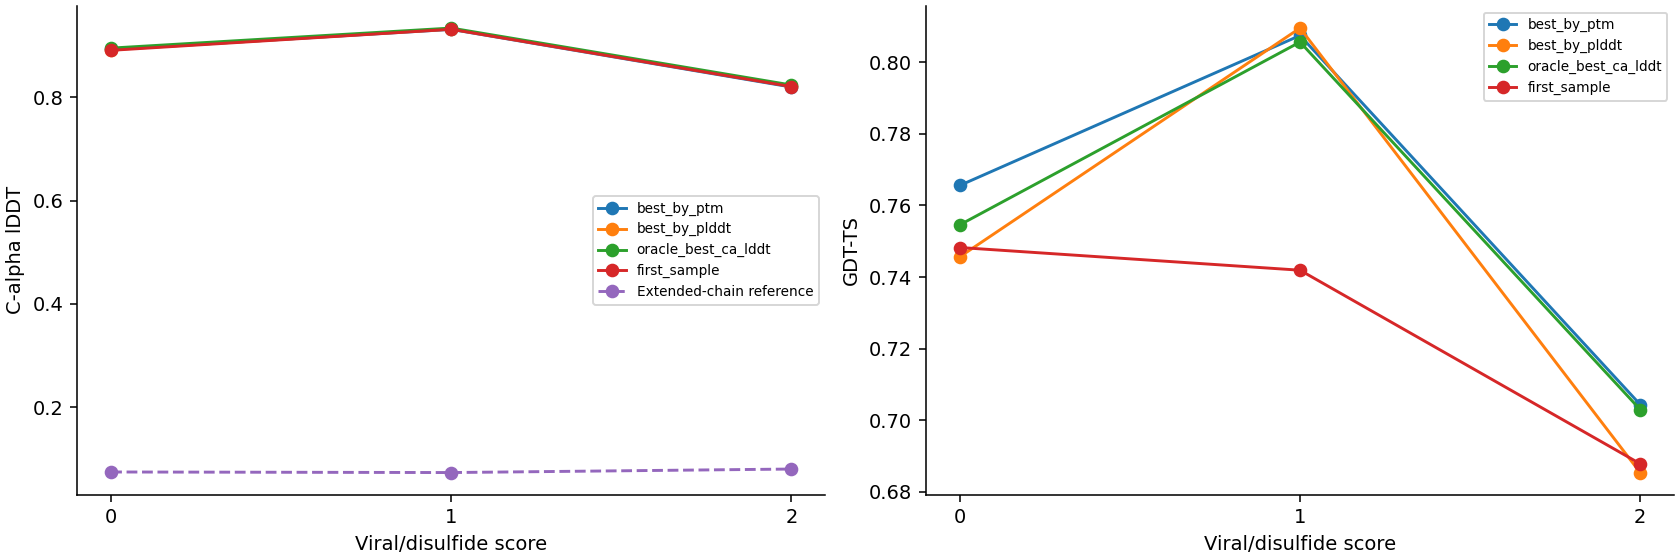

{'n_top': 8,
 'n_lower': 28,
 'mean': -0.092661185057074,
 'ci_low': -0.27991150492214373,
 'ci_high': 0.05623732179050575}

{'n': 36,
 'coef': -0.04776104755634425,
 'se': nan,
 't': nan,
 'controls': ['log_len',
  'resolution',
  'viral_axis_virus_or_phage',
  'viral_axis_disulfide_dense']}

In [10]:
policies=['best_by_ptm','best_by_plddt','oracle_best_ca_lddt','first_sample']
curves=[];effects=[];selected_tables=[]
for policy in policies:
    curve,effect=summarize_selection(features,samples,policy)
    curves.append(curve);effects.append(effect)
    selected=select_rows(samples,policy)
    selected_tables.append(features.merge(selected,on='target_id',suffixes=('','_result'),validate='one_to_one'))
curve_table=pd.concat(curves,ignore_index=True)
selected_targets=pd.concat(selected_tables,ignore_index=True)
display(curve_table);display(pd.DataFrame(effects))
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for policy,part in curve_table.groupby('selection',sort=False):
    axes[0].plot(part.viral_disulfide_score,part.ca_lddt_mean,marker='o',label=policy)
    axes[1].plot(part.viral_disulfide_score,part.gdt_ts_mean,marker='o',label=policy)
primary_curve=curve_table[curve_table.selection.eq('best_by_ptm')]
axes[0].plot(primary_curve.viral_disulfide_score,primary_curve.baseline_ca_lddt_mean,'--o',label='Extended-chain reference')
for ax,label in zip(axes,['C-alpha lDDT','GDT-TS']):
    ax.set(xlabel='Viral/disulfide score',ylabel=label,xticks=[0,1,2]);ax.spines[['top','right']].set_visible(False);ax.legend(fontsize=7)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
primary=effects[0]
display(primary['bootstrap_top_minus_lower_ca_lddt']);display(primary['adjusted_len_res_method'])


## 6. What the agent decided, and why

Evaluate the calculated contrast and its interval, with the pilot sample size shown explicitly.


In [11]:
contrast=primary['top_minus_lower_ca_lddt'];interval=primary['bootstrap_top_minus_lower_ca_lddt'];n_top=primary['n_top']
if contrast<0 and interval['ci_high']<0:
    decision='The pilot supports lower accuracy for the combined viral and disulfide-dense regime.'
elif contrast<0:
    decision='The pilot points toward lower accuracy, but its interval does not resolve the contrast.'
else:decision='The pilot does not support lower accuracy in the combined regime.'
print(decision)
print(f'Top regime n={n_top}; top-minus-lower C-alpha lDDT={contrast:.6f};95% interval=[{interval["ci_low"]:.6f},{interval["ci_high"]:.6f}].')
print('This conclusion is limited to the pilot sample; the top regime has',n_top,'targets.')
output=CALC_ROOT/'axis-10';output.mkdir(parents=True,exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False);selected_targets.to_csv(output/'selected_scores.csv',index=False);curve_table.to_csv(output/'curves.csv',index=False)
(output/'effects.json').write_text(json.dumps(effects,indent=2))
receipt={'analysis_id':'esmfold2-featured/test-10','completed':True,'sources':source_receipts,'scores_sha256':sha256_file(score_source),'targets':len(features),'new_inference_executed':False,'calculation_scope':'sequence/experimental-chain processing, axis construction, released per-sample measurements, selection policies, curves and adjusted controls','decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


The pilot points toward lower accuracy, but its interval does not resolve the contrast.
Top regime n=8; top-minus-lower C-alpha lDDT=-0.092221;95% interval=[-0.279912,0.056237].
This conclusion is limited to the pilot sample; the top regime has 8 targets.


7052